In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
t, r, p, s = 1.0, 0.9, 0.2, 0.0

In [ ]:
d_values = np.linspace(0.1, 0.99, 10)

In [4]:
df_00 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[0][0] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[0][0] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[0][0] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[0][0] for d in d_values],
}
df_01 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[0][1] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[0][1] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[0][1] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[0][1] for d in d_values],
}
df_10 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[1][0] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[1][0] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[1][0] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[1][0] for d in d_values],
}
df_11 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[1][1] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[1][1] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[1][1] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[1][1] for d in d_values],
}

In [7]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.0001
d = 0.7
alpha = 0.3
bound = 1 / (1 - d)

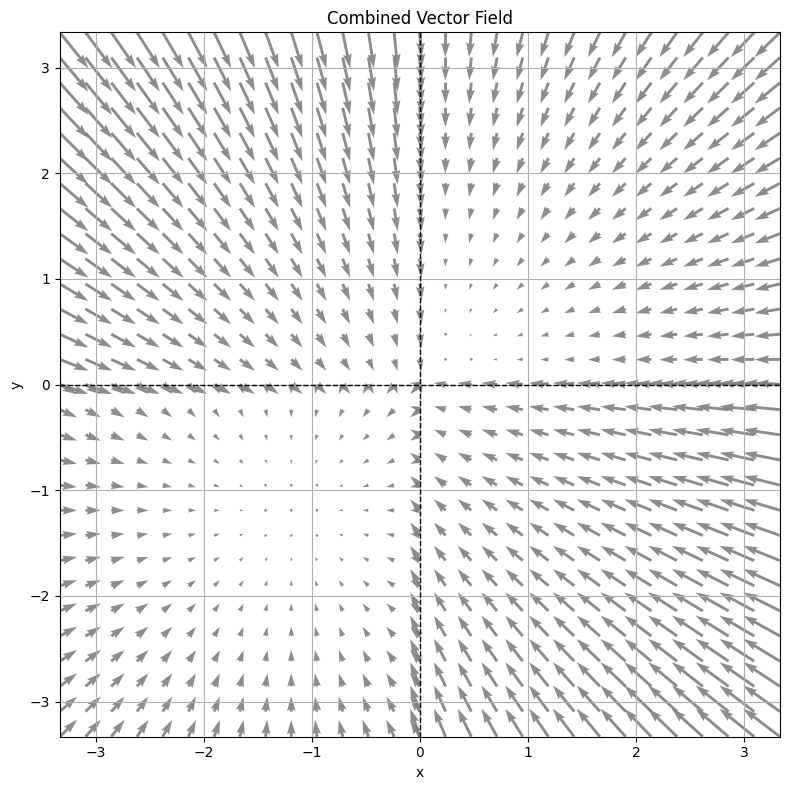

In [36]:
# Precompute Q-values
Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[0]
Q_AD = QvaluesADvs00(t, r, p, s, epsilon, d)[0]

# Define vector field functions
def field1(x, y):
    u = alpha * (Q_GT[0] - Q_GT[1] - x)
    v = alpha * (Q_AD[0] - Q_AD[1] - y)
    return u, v

def field2(x, y):
    u = alpha * (Q_GT[0] - Q_GT[1] - x)
    v = alpha * (Q_GT[0] - Q_GT[1] - y)
    return u, v

def field3(x, y):
    u = alpha * (Q_AD[0] - Q_AD[1] - x)
    v = alpha * (Q_AD[0] - Q_AD[1] - y)
    return u, v

def field4(x, y):
    u = alpha * (Q_AD[0] - Q_AD[1] - x)
    v = alpha * (Q_GT[0] - Q_GT[1] - y)
    return u, v

# Helper to draw a vector field over a region
def add_vector_field(ax, field_func, x_range, y_range, density=15):
    x_vals = np.linspace(*x_range, density)
    y_vals = np.linspace(*y_range, density)
    X, Y = np.meshgrid(x_vals, y_vals)
    U, V = field_func(X, Y)
    ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=4, facecolor='grey', alpha=0.9)

# Create single combined plot
fig, ax = plt.subplots(figsize=(8, 8))

# Add all vector fields to the same axes
add_vector_field(ax, field1, (0, bound), (-bound, 0))
add_vector_field(ax, field4, (-bound, 0), (0, bound))
add_vector_field(ax, field3, (0, bound), (0, bound))
add_vector_field(ax, field2, (-bound, 0), (-bound, 0))


# Add formatting
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_xlim(-bound, bound)
ax.set_ylim(-bound, bound)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Combined Vector Field')
ax.grid(True)

plt.tight_layout()
plt.show()


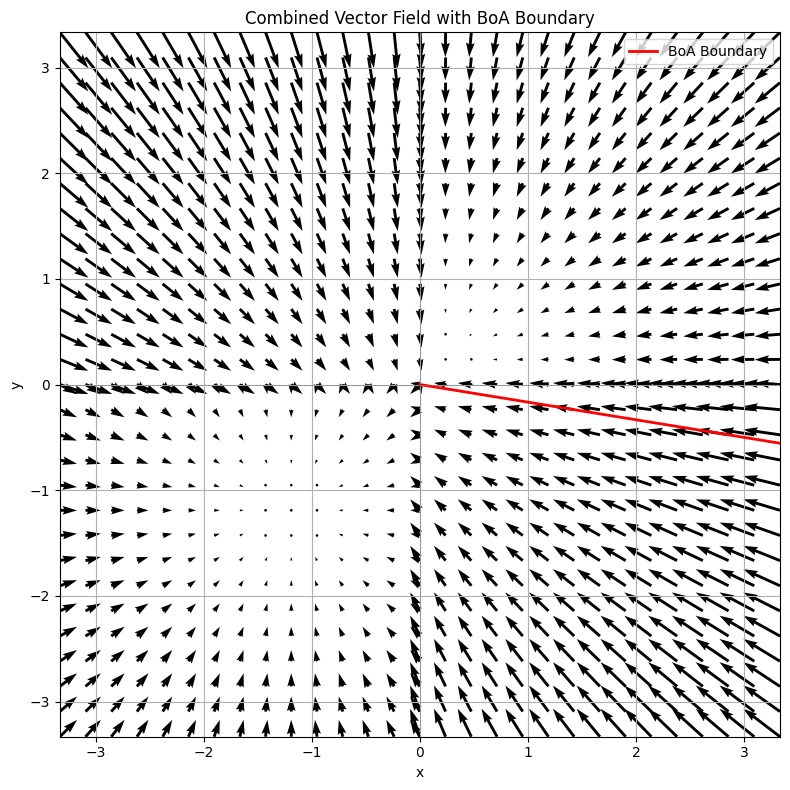

In [37]:
# Get Q-values
Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[0]
Q_AD = QvaluesADvs00(t, r, p, s, epsilon, d)[0]

# Delta values
dx = Q_GT[0] - Q_GT[1]
dy = Q_AD[0] - Q_AD[1]

# Safe scaling
eps = 1e-8
inv_scale_dx = 1 / ((1 - d) * abs(dx) + eps)
inv_scale_dy = 1 / ((1 - d) * abs(dy) + eps)
a = min(inv_scale_dx, inv_scale_dy)

# Boundary endpoint
end_x = -a * dx
end_y = -a * dy

# Vector field functions
def field1(x, y): return alpha * (dx - x), alpha * (dy - y)
def field2(x, y): return alpha * (dx - x), alpha * (dx - y)
def field3(x, y): return alpha * (dy - x), alpha * (dy - y)
def field4(x, y): return alpha * (dy - x), alpha * (dx - y)

# Helper function to add a quiver field to an axis
def add_vector_field(ax, field_func, x_range, y_range, density=15):
    x_vals = np.linspace(*x_range, density)
    y_vals = np.linspace(*y_range, density)
    X, Y = np.meshgrid(x_vals, y_vals)
    U, V = field_func(X, Y)
    ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=4)

# Unified plot
fig, ax = plt.subplots(figsize=(8, 8))

# Add vector fields in four quadrants
# Add all vector fields to the same axes
add_vector_field(ax, field1, (0, bound), (-bound, 0))
add_vector_field(ax, field4, (-bound, 0), (0, bound))
add_vector_field(ax, field3, (0, bound), (0, bound))
add_vector_field(ax, field2, (-bound, 0), (-bound, 0))
# Add BoA boundary line
ax.plot([0, end_x], [0, end_y], color='red', linewidth=2, label='BoA Boundary')

# Axes, range, and labels
ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.5)
ax.set_xlim(-bound, bound)
ax.set_ylim(-bound, bound)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Combined Vector Field with BoA Boundary')
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()


In [10]:
# Deltas
dx = Q_GT[0] - Q_GT[1]
dy = Q_AD[0] - Q_AD[1]

# Safe inverse scales
eps = 1e-8
inv_scale_dx = 1 / ((1 - d) * abs(dx) + eps)
inv_scale_dy = 1 / ((1 - d) * abs(dy) + eps)
a = min(inv_scale_dx, inv_scale_dy)

# Final result
result = 0.5 * a**2 * abs(dx) * abs(dy) * (1 - d)**2

print("Result:", result)

Result: 0.08336250152574608


In [38]:
algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        random_uniform=False, tolerance=1e-10000, 
        M=int(5), verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()    

In [39]:
exp = 2

In [40]:
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]

In [41]:
q1['StateC'] = q1['Q1'] - q1['Q3']
q1['StateD'] = q1['Q2'] - q1['Q4']
q2['StateC'] = q2['Q1'] - q2['Q3']
q2['StateD'] = q2['Q2'] - q2['Q4']

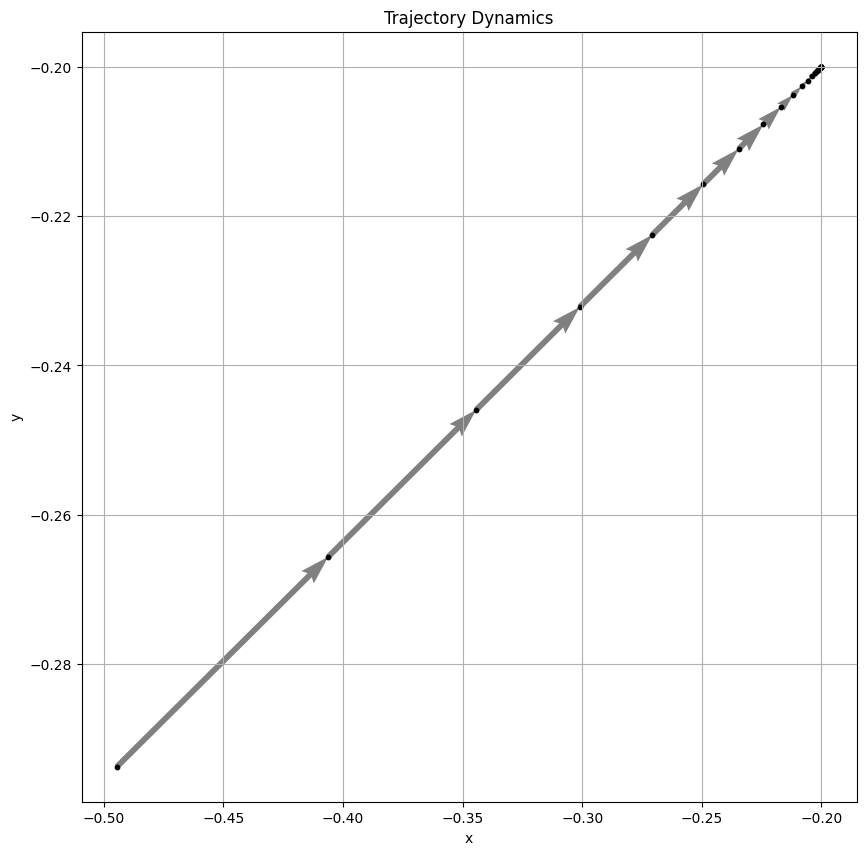

In [43]:
trajectory_dinamics_plot(x, y)

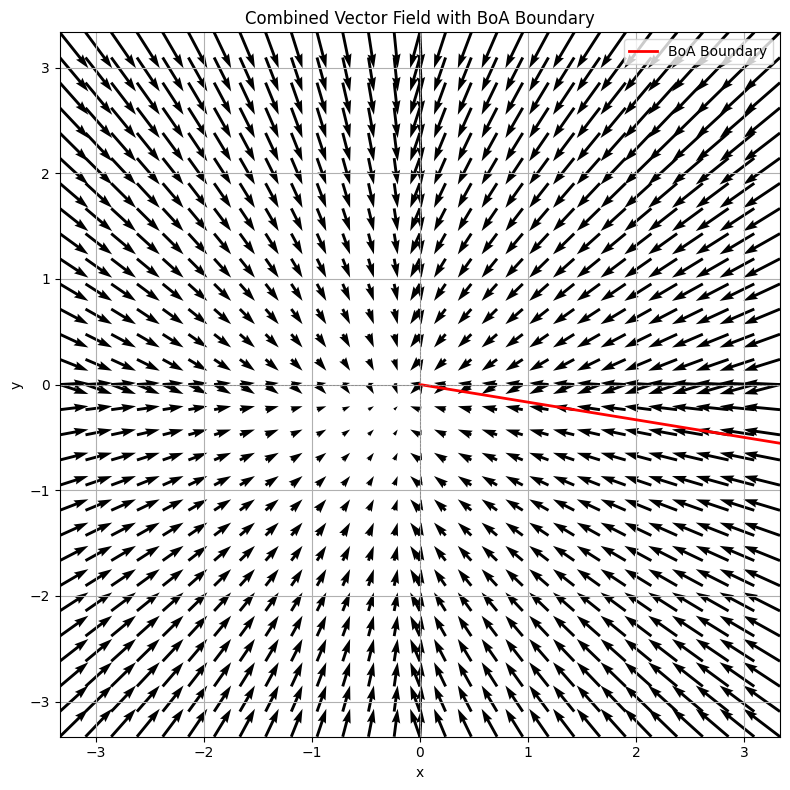

In [ ]:
u = x[1:] - x[:-1]
v = y[1:] - y[:-1]

# Get Q-values
Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[0]
Q_AD = QvaluesADvs00(t, r, p, s, epsilon, d)[0]

# Delta values
dx = Q_GT[0] - Q_GT[1]
dy = Q_AD[0] - Q_AD[1]

# Safe scaling
eps = 1e-8
inv_scale_dx = 1 / ((1 - d) * abs(dx) + eps)
inv_scale_dy = 1 / ((1 - d) * abs(dy) + eps)
a = min(inv_scale_dx, inv_scale_dy)

# Boundary endpoint
end_x = -a * dx
end_y = -a * dy

# Vector field functions
def field1(x, y): return alpha * (dx - x), alpha * (dy - y)
def field2(x, y): return alpha * (dx - x), alpha * (dx - y)
def field3(x, y): return alpha * (dy - x), alpha * (dy - y)
def field4(x, y): return alpha * (dy - x), alpha * (dx - y)

# Helper function to add a quiver field to an axis
def add_vector_field(ax, field_func, x_range, y_range, density=15):
    x_vals = np.linspace(*x_range, density)
    y_vals = np.linspace(*y_range, density)
    X, Y = np.meshgrid(x_vals, y_vals)
    U, V = field_func(X, Y)
    ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=4)

# Unified plot
fig, ax = plt.subplots(figsize=(8, 8))


# Add vector fields in four quadrants
add_vector_field(ax, field1, (0, bound), (-bound, 0))
add_vector_field(ax, field2, (-bound, 0), (-bound, 0))
add_vector_field(ax, field3, (0, bound), (0, bound))
add_vector_field(ax, field4, (-bound, 0), (0, bound))

# Add BoA boundary line
ax.plot([0, end_x], [0, end_y], color='red', linewidth=2, label='BoA Boundary')

# Axes, range, and labels
ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.5)
ax.set_xlim(-bound, bound)
ax.set_ylim(-bound, bound)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Combined Vector Field with BoA Boundary')
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
# If you see crossing the red line error!!